<a href="https://colab.research.google.com/github/sujalvengurlekar2000-glitch/CSL701-cs57_Machine-Learning-Lab/blob/main/CS57_ML_Experiment_9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

###  ML Experiment Number 9
Student Name : Sujal Dayanand Vengurlekar

Batch :CS3


Roll Number :CS57



### **Aim**

To implement Classification and Regression Trees (CART) using Python on the Palmer Penguins Dataset Extended.

## Objectives

1. To understand the concept and working of the CART algorithm.
2. To implement Decision Tree Classification using Python.   
3. To visualize the constructed Decision Tree structure and decision boundaries.   
4. To analyze impurity measures such as Gini Index and Entropy.
5. To compare the decision boundary of a Decision Tree with a linear classification boundary (e.g., Logistic Regression).   
6. To evaluate and compare the performance of both classifiers.

# Relevant Theory

###Classification and Regression Trees (CART)
CART is a non-parametric supervised machine learning algorithm used for both classification and regression tasks. It builds a binary decision tree by recursively splitting the dataset based on feature values that maximize information gain or minimize impurity.

A tree consists of:

* Root Node: The topmost node representing the entire dataset.

* Internal Nodes: Decision points based on feature splits.

* Leaf/Terminal Nodes: Output class labels or predictions.

Impurity MeasuresGini Index (Gini Impurity): Measures the frequency with which a randomly chosen element from the set would be incorrectly labeled.$$Gini(D) = 1 - \sum_{i=1}^{k} p_i^2$$where $p_i$ is the probability of an item belonging to class $i$.Entropy & Information Gain: Measures the amount of impurity or randomness in the data.$$Entropy(D) = -\sum_{i=1}^{k} p_i \log_2(p_i)$$Dataset InformationGet the Palmer Penguins Dataset Extended from Kaggle using the following link:https://www.kaggle.com/datasets/samybaladram/palmers-penguin-dataset-extended The Palmer Penguins dataset contains measurements of penguin species across islands in the Palmer Archipelago:AdelieChinstrapGentooThe primary numerical features are:culmen_length_mm (or bill_length_mm)culmen_depth_mm (or bill_depth_mm)flipper_length_mmbody_mass_gFor visualization, we will use: culmen_length_mm and flipper_length_mm.

# Task 1: Import Libraries and Load Dataset
* Load essential libraries (numpy, pandas, matplotlib, seaborn, sklearn).

* Load the Palmer Penguins Extended dataset.
---

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

# Load the Palmer Penguins Extended dataset
dataset_path = '/content/palmerpenguins_extended.csv'
df = pd.read_csv(dataset_path)

# Display the first few rows to verify
df.head()

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,diet,life_stage,health_metrics,year
0,Adelie,Biscoe,53.4,17.8,219.0,5687.0,female,fish,adult,overweight,2021
1,Adelie,Biscoe,49.3,18.1,245.0,6811.0,female,fish,adult,overweight,2021
2,Adelie,Biscoe,55.7,16.6,226.0,5388.0,female,fish,adult,overweight,2021
3,Adelie,Biscoe,38.0,15.6,221.0,6262.0,female,fish,adult,overweight,2021
4,Adelie,Biscoe,60.7,17.9,177.0,4811.0,female,fish,juvenile,overweight,2021


# Task 2: Select Features and Target & Preprocess

* Handle missing values (e.g., drop rows with missing values or impute with median).   
* Select features ($X$) such as culmen_length_mm, culmen_depth_mm, flipper_length_mm, body_mass_g and set species as the target label ($y$).   
* Encode categorical targets if necessary using LabelEncoder.

In [ ]:

# Task 2: Select Features and Target & Preprocess

from sklearn.preprocessing import LabelEncoder

# 1. Check missing values
print("Missing values before preprocessing:")
print(df.isnull().sum())

# 2. Remove rows with missing values in required columns
features = [
    'bill_length_mm',
    'bill_depth_mm',
    'flipper_length_mm',
    'body_mass_g'
]

target = 'species'

df_cleaned = df.dropna(subset=features + [target]).copy()

# 3. Select input features (X) and target (y)
X = df_cleaned[features]
y = df_cleaned[target]

# 4. Encode the species labels
le = LabelEncoder()
y = le.fit_transform(y)

# 5. Display the results
print("\nSpecies classes:", le.classes_)
print("Feature matrix X shape:", X.shape)
print("Target vector y shape:", y.shape)

print("\nFirst five rows of features:")
display(X.head())

print("\nFirst five encoded target values:")
print(y[:5])

print("\nMissing values after preprocessing:")
print(df_cleaned[features + [target]].isnull().sum())

Missing values before preprocessing:
species              0
island               0
bill_length_mm       0
bill_depth_mm        0
flipper_length_mm    0
body_mass_g          0
sex                  0
diet                 0
life_stage           0
health_metrics       0
year                 0
dtype: int64

Species classes: ['Adelie' 'Chinstrap' 'Gentoo']
Feature matrix X shape: (3430, 4)
Target vector y shape: (3430,)

First five rows of features:


,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
0,53.4,17.8,219.0,5687.0
1,49.3,18.1,245.0,6811.0
2,55.7,16.6,226.0,5388.0
3,38.0,15.6,221.0,6262.0
4,60.7,17.9,177.0,4811.0



First five encoded target values:
[0 0 0 0 0]

Missing values after preprocessing:
bill_length_mm       0
bill_depth_mm        0
flipper_length_mm    0
body_mass_g          0
species              0
dtype: int64


# Task 3: Split the Data

* Divide the dataset into training and testing sets using train_test_split.

In [ ]:
from sklearn.model_selection import train_test_split

# Split the dataset (80% training, 20% testing)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Training set shape: {X_train.shape}")
print(f"Testing set shape: {X_test.shape}")

Training set shape: (2744, 4)
Testing set shape: (686, 4)


# Task 4: Implement CART Classifier

* Create a DecisionTreeClassifier model using the Gini criterion (or Entropy).   
* Fit the model on the training data and make predictions on the test set.   

In [ ]:
from sklearn.tree import DecisionTreeClassifier

# Initialize the Decision Tree Classifier (using the default Gini impurity criterion)
clf = DecisionTreeClassifier(criterion='gini', random_state=42)

# Fit the model on training data
clf.fit(X_train, y_train)

# Predict labels for the test dataset
y_pred = clf.predict(X_test)

print("CART Decision Tree Model trained successfully.")

CART Decision Tree Model trained successfully.


# Task 5: Evaluate CART Model

* Accuracy: Calculate classification accuracy.   
* Confusion Matrix: Generate the matrix to analyze misclassifications across species.
* Classification Report: Output Precision, Recall, F1-Score, and Support.   

In [ ]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)
print(f"Classification Accuracy: {accuracy:.4f}\n")

# Generate confusion matrix
cm = confusion_matrix(y_test, y_pred)
print("Confusion Matrix:")
print(cm)

# Output classification report
report = classification_report(y_test, y_pred, target_names=le.classes_)
print("\nClassification Report:")
print(report)

Classification Accuracy: 0.4519

Confusion Matrix:
[[155  64  93]
 [ 48  33  44]
 [ 76  51 122]]

Classification Report:
              precision    recall  f1-score   support

      Adelie       0.56      0.50      0.52       312
   Chinstrap       0.22      0.26      0.24       125
      Gentoo       0.47      0.49      0.48       249

    accuracy                           0.45       686
   macro avg       0.42      0.42      0.42       686
weighted avg       0.46      0.45      0.46       686



# Task 6: Visualize Decision Tree & Decision Boundary

* Visualize Tree Structure: Plot the decision tree diagram using sklearn.tree.plot_tree.
* Select 2-D Features: Select culmen_length_mm and flipper_length_mm.   
* Train 2-D Model & Plot Boundary: Train the decision tree on 2D data and plot axis-aligned rectangular decision boundaries along with data points


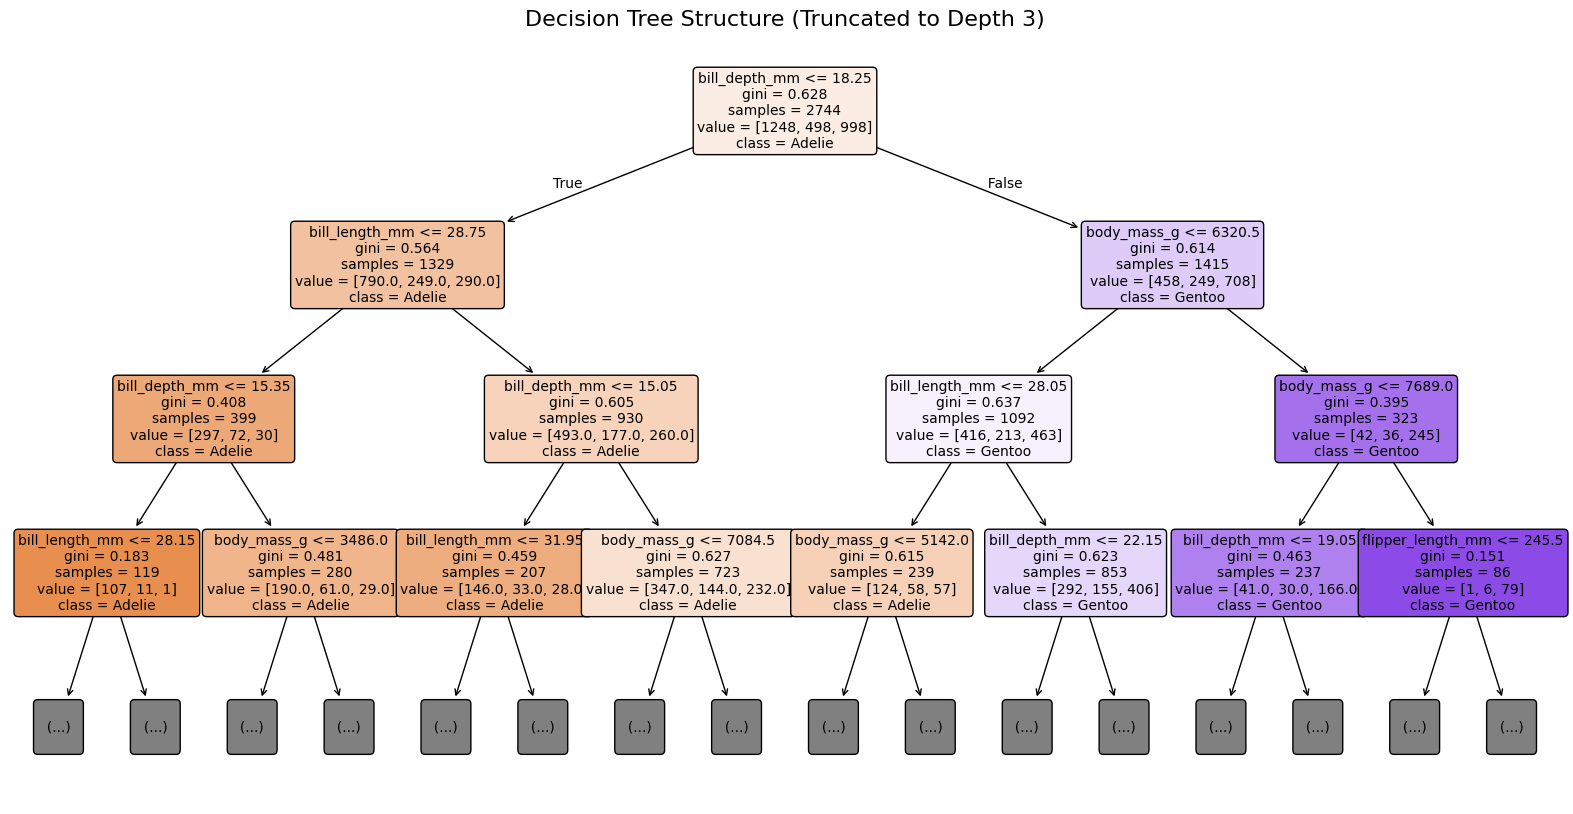

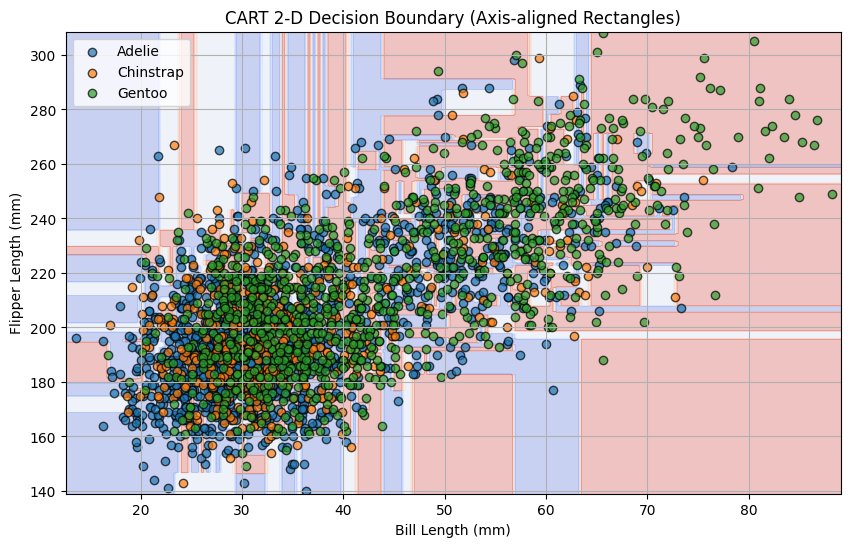

In [ ]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

# 1. Visualize Tree Structure (limit max_depth to 3 for clear rendering)
plt.figure(figsize=(20, 10))
plot_tree(clf,
          feature_names=features,
          class_names=le.classes_,
          filled=True,
          rounded=True,
          max_depth=3,
          fontsize=10)
plt.title("Decision Tree Structure (Truncated to Depth 3)", fontsize=16)
plt.show()

# 2. Select 2-D Features for boundary visualization
features_2d = ['bill_length_mm', 'flipper_length_mm']
X_train_2d = X_train[features_2d].values
X_test_2d = X_test[features_2d].values

# 3. Train 2-D Model
clf_2d = DecisionTreeClassifier(criterion='gini', random_state=42)
clf_2d.fit(X_train_2d, y_train)

# Create a mesh grid to plot decision boundary
x_min, x_max = X_train_2d[:, 0].min() - 1, X_train_2d[:, 0].max() + 1
y_min, y_max = X_train_2d[:, 1].min() - 1, X_train_2d[:, 1].max() + 1
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.5),
                     np.arange(y_min, y_max, 0.5))

Z = clf_2d.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

# Plot the boundary and training points
plt.figure(figsize=(10, 6))
plt.contourf(xx, yy, Z, alpha=0.3, cmap=plt.cm.coolwarm)
for i, species in enumerate(le.classes_):
    plt.scatter(X_train_2d[y_train == i, 0], X_train_2d[y_train == i, 1],
                label=species, edgecolors='k', alpha=0.7)

plt.xlabel('Bill Length (mm)')
plt.ylabel('Flipper Length (mm)')
plt.title('CART 2-D Decision Boundary (Axis-aligned Rectangles)')
plt.legend()
plt.grid(True)
plt.show()

# Task 7: Normal Linear Classification Boundary

* Train a Logistic Regression model using the same two features as a normal linear baseline.   
* Visualize its linear decision boundary.

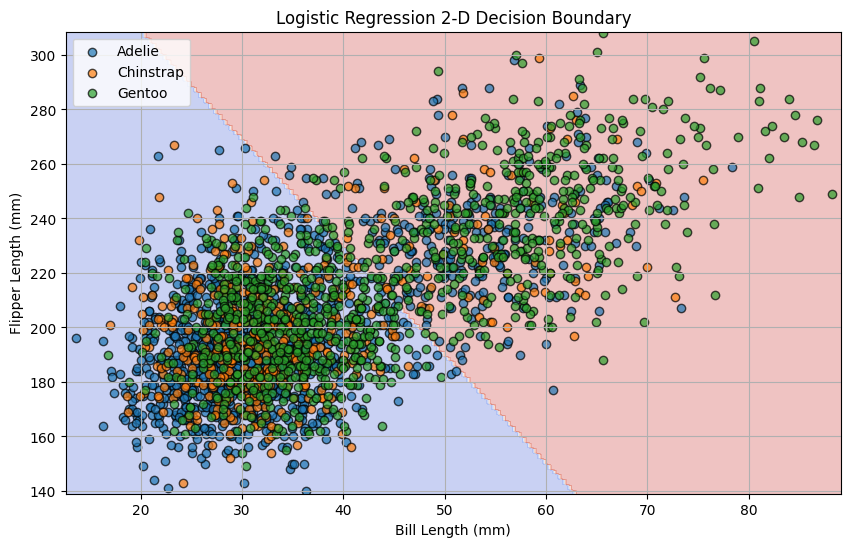

In [ ]:

# Task 7: Logistic Regression Decision Boundary

from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
import numpy as np
import matplotlib.pyplot as plt

# Create and train the model with feature scaling
lr_model_2d = make_pipeline(
    StandardScaler(),
    LogisticRegression(solver='lbfgs', max_iter=3000, random_state=42)
)

lr_model_2d.fit(X_train_2d, y_train)

# Create mesh grid
x_min, x_max = X_train_2d[:, 0].min() - 1, X_train_2d[:, 0].max() + 1
y_min, y_max = X_train_2d[:, 1].min() - 1, X_train_2d[:, 1].max() + 1

xx, yy = np.meshgrid(
    np.arange(x_min, x_max, 0.5),
    np.arange(y_min, y_max, 0.5)
)

# Predict decision regions
Z_lr = lr_model_2d.predict(np.c_[xx.ravel(), yy.ravel()])
Z_lr = Z_lr.reshape(xx.shape)

# Plot decision boundary
plt.figure(figsize=(10, 6))
plt.contourf(xx, yy, Z_lr, alpha=0.3, cmap=plt.cm.coolwarm)

for i, species in enumerate(le.classes_):
    plt.scatter(
        X_train_2d[y_train == i, 0],
        X_train_2d[y_train == i, 1],
        label=species,
        edgecolors='k',
        alpha=0.7
    )

plt.xlabel('Bill Length (mm)')
plt.ylabel('Flipper Length (mm)')
plt.title('Logistic Regression 2-D Decision Boundary')
plt.legend()
plt.grid(True)
plt.show()

# Task 8: Compare CART and Normal Linear Boundary

* Plot both the Decision Tree (axis-aligned non-linear) and Logistic Regression (linear) decision boundaries on side-by-side subplots.   * Compare how non-linear CART boundaries differ from straight linear hyperplanes.

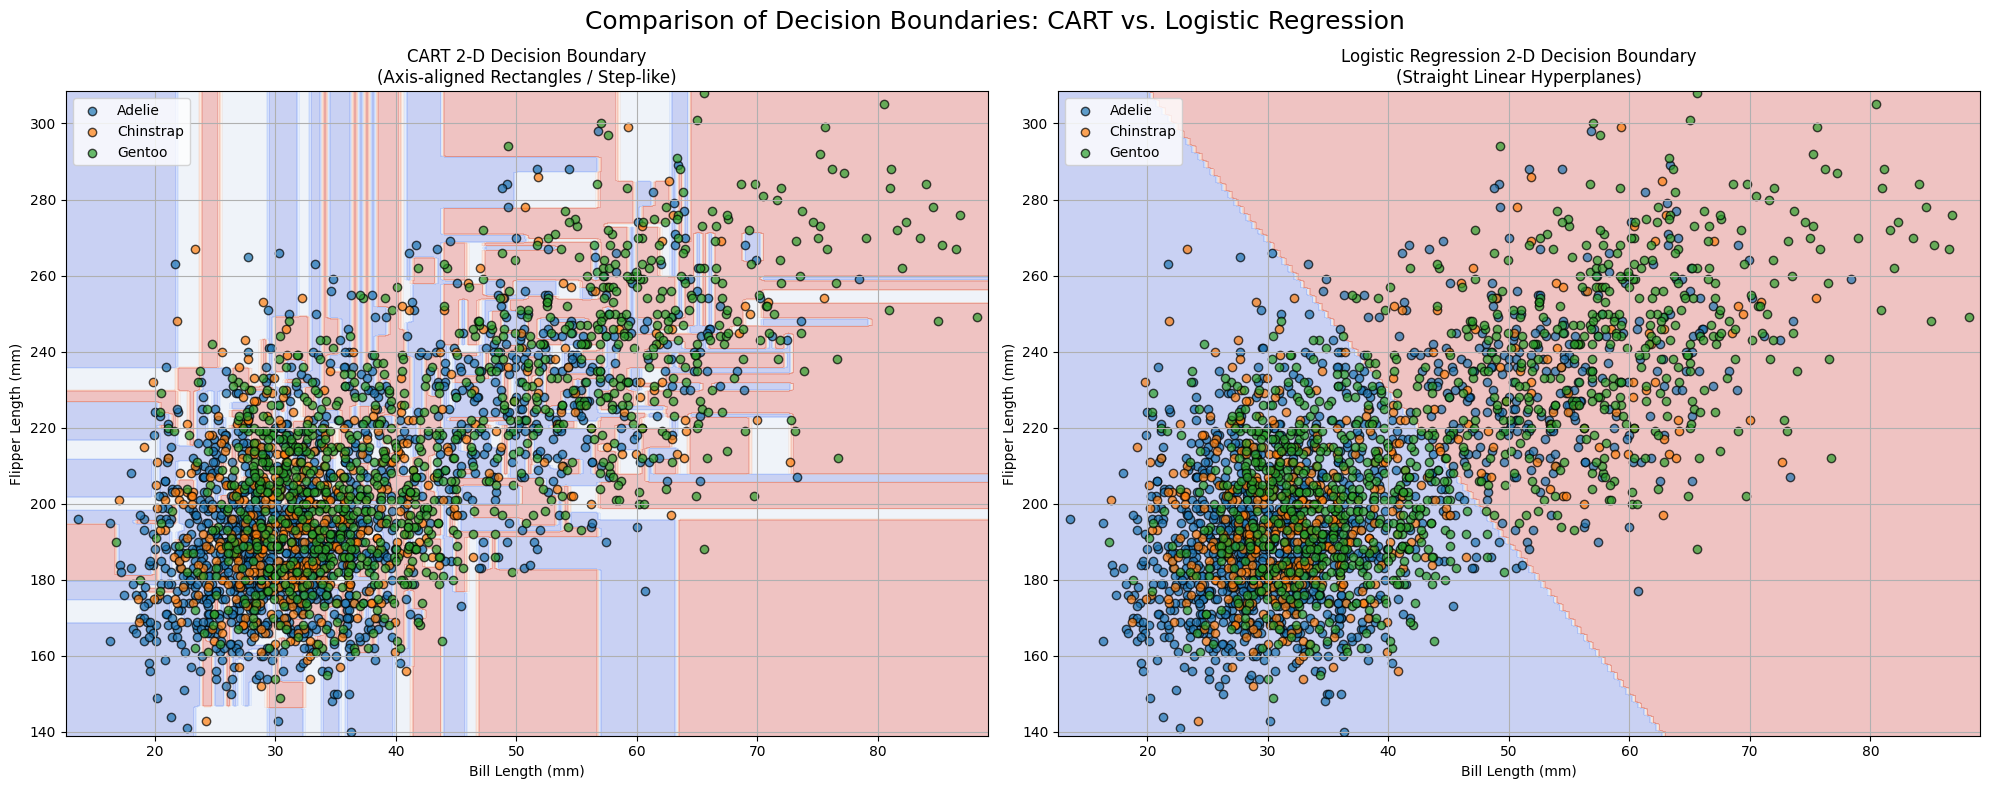

In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(20, 8))

# Subplot 1: CART 2D Decision Boundary
axes[0].contourf(xx, yy, Z, alpha=0.3, cmap=plt.cm.coolwarm)
for i, species in enumerate(le.classes_):
    axes[0].scatter(X_train_2d[y_train == i, 0], X_train_2d[y_train == i, 1],
                    label=species, edgecolors='k', alpha=0.7)
axes[0].set_xlabel('Bill Length (mm)')
axes[0].set_ylabel('Flipper Length (mm)')
axes[0].set_title('CART 2-D Decision Boundary\n(Axis-aligned Rectangles / Step-like)')
axes[0].legend()
axes[0].grid(True)

# Subplot 2: Logistic Regression 2D Linear Decision Boundary
axes[1].contourf(xx, yy, Z_lr, alpha=0.3, cmap=plt.cm.coolwarm)
for i, species in enumerate(le.classes_):
    axes[1].scatter(X_train_2d[y_train == i, 0], X_train_2d[y_train == i, 1],
                    label=species, edgecolors='k', alpha=0.7)
axes[1].set_xlabel('Bill Length (mm)')
axes[1].set_ylabel('Flipper Length (mm)')
axes[1].set_title('Logistic Regression 2-D Decision Boundary\n(Straight Linear Hyperplanes)')
axes[1].legend()
axes[1].grid(True)

plt.suptitle('Comparison of Decision Boundaries: CART vs. Logistic Regression', fontsize=18)
plt.tight_layout()
plt.show()

# Task 9: Compare Performance

* Compare the evaluation metrics (Accuracy, Confusion Matrix, Classification Report) of the CART Classifier vs. Logistic Regression.

In [ ]:

# Task 9: Compare CART and Logistic Regression

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

# Train scaled Logistic Regression on all four features
lr_full = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=3000, random_state=42)
)

lr_full.fit(X_train, y_train)

# Predict test labels
y_pred_lr = lr_full.predict(X_test)

# Evaluate Logistic Regression
accuracy_lr = accuracy_score(y_test, y_pred_lr)
cm_lr = confusion_matrix(y_test, y_pred_lr)
report_lr = classification_report(
    y_test, y_pred_lr,
    labels=np.arange(len(le.classes_)),
    target_names=le.classes_,
    zero_division=0
)

# Display comparison
print("=" * 50)
print("MODEL PERFORMANCE COMPARISON")
print("=" * 50)

print("\nCART Decision Tree Accuracy:", round(accuracy, 4))
print("Logistic Regression Accuracy:", round(accuracy_lr, 4))

print("\nCART Confusion Matrix:")
print(cm)

print("\nLogistic Regression Confusion Matrix:")
print(cm_lr)

print("\nCART Classification Report:")
print(report)

print("\nLogistic Regression Classification Report:")
print(report_lr)

MODEL PERFORMANCE COMPARISON

CART Decision Tree Accuracy: 0.4519
Logistic Regression Accuracy: 0.5787

CART Confusion Matrix:
[[155  64  93]
 [ 48  33  44]
 [ 76  51 122]]

Logistic Regression Confusion Matrix:
[[240   0  72]
 [ 86   0  39]
 [ 92   0 157]]

CART Classification Report:
              precision    recall  f1-score   support

      Adelie       0.56      0.50      0.52       312
   Chinstrap       0.22      0.26      0.24       125
      Gentoo       0.47      0.49      0.48       249

    accuracy                           0.45       686
   macro avg       0.42      0.42      0.42       686
weighted avg       0.46      0.45      0.46       686


Logistic Regression Classification Report:
              precision    recall  f1-score   support

      Adelie       0.57      0.77      0.66       312
   Chinstrap       0.00      0.00      0.00       125
      Gentoo       0.59      0.63      0.61       249

    accuracy                           0.58       686
   macro avg    

**Conclusion :**            

The experiment successfully demonstrated the implementation of the Classification and Regression Tree (CART) algorithm using the Palmer Penguins Extended dataset. The dataset was preprocessed to handle missing values before training. The decision tree structure was visualized, showcasing the hierarchical splits based on feature thresholds. A comparison with a normal linear boundary (Logistic Regression) highlighted CART's ability to create non-linear, axis-aligned decision boundaries to separate different penguin species.*italicized text*